# 43 -- Full hyperbolic RBM on the 1k x 1k subset (e_plus / e_minus encoding)

e_plus reproduces the R baseline RBM (RMSE 0.8431 / MAE 0.6481) trained on `a`. e_minus trains the
same architecture on the per-user mean rating `b_u`, masked to the same rated-cell positions. The
RBM class, data loading, split and normalization below are copied unchanged from
`26_drbm_energy_cd1_training.ipynb`, which produced the R baseline this notebook reproduces as a
checkpoint before training the hyperbolic e_minus channel.

## Setup -- data loading, split, normalization (copied from notebook 26, unchanged)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
data_dir = root / "data"
out_dir = root / "outputs"
out_dir.mkdir(parents=True, exist_ok=True)

torch.manual_seed(42)

train_hyp = pd.read_csv(data_dir / "train_hyperbolic.csv")
test_hyp = pd.read_csv(data_dir / "test_hyperbolic.csv")
print(f"train_hyperbolic: {len(train_hyp):,} rows   test_hyperbolic: {len(test_hyp):,} rows")

EXPECTED_TRAIN, EXPECTED_TEST = 492055, 123474
if len(train_hyp) != EXPECTED_TRAIN or len(test_hyp) != EXPECTED_TEST:
    raise SystemExit(
        f"STOP: row counts differ from spec. expected train={EXPECTED_TRAIN:,} test={EXPECTED_TEST:,}, "
        f"got train={len(train_hyp):,} test={len(test_hyp):,}"
    )
print(f"confirmed: {len(train_hyp):,} training ratings, {len(test_hyp):,} test ratings")

all_users = sorted(pd.concat([train_hyp["userId"], test_hyp["userId"]]).unique())
all_movies = sorted(pd.concat([train_hyp["movieId"], test_hyp["movieId"]]).unique())
n_users, n_movies = len(all_users), len(all_movies)
user_to_row = {u: i for i, u in enumerate(all_users)}
movie_to_col = {m: j for j, m in enumerate(all_movies)}
print(f"n_users={n_users}  n_movies={n_movies}")

train_hyperbolic: 492,055 rows   test_hyperbolic: 123,474 rows
confirmed: 492,055 training ratings, 123,474 test ratings
n_users=1000  n_movies=1000


## RBM class (copied unchanged from notebook 26)

Manual CD-1, masked. `W` is the channel weight matrix, `hbias` is the hidden bias (`c` on the page),
`vbias` is the visible bias (`d` on the page).

In [2]:
class RBM:
    def __init__(self, n_visible, n_hidden, seed=42, device="cpu"):
        g = torch.Generator(device=device).manual_seed(seed)
        self.n_visible = n_visible
        self.n_hidden = n_hidden
        self.device = device
        self.W = (torch.randn(n_visible, n_hidden, generator=g, device=device) * 0.01)
        self.vbias = torch.zeros(n_visible, device=device)
        self.hbias = torch.zeros(n_hidden, device=device)

    def sample_h(self, v):
        h_prob = torch.sigmoid(v @ self.W + self.hbias)
        h_sample = torch.bernoulli(h_prob)
        return h_prob, h_sample

    def sample_v(self, h):
        return torch.sigmoid(h @ self.W.t() + self.vbias)

    def reconstruct(self, v, mask=None):
        """Deterministic (mean-field) forward+backward pass -- used for prediction, not training."""
        h_prob = torch.sigmoid(v @ self.W + self.hbias)
        v_prob = torch.sigmoid(h_prob @ self.W.t() + self.vbias)
        if mask is not None:
            v_prob = v_prob * mask
        return v_prob

    def cd1_step(self, v0, mask, lr):
        bs = v0.shape[0]
        h0_prob, h0_sample = self.sample_h(v0)
        v1_prob = self.sample_v(h0_sample) * mask
        h1_prob, _ = self.sample_h(v1_prob)

        pos = v0.t() @ h0_prob
        neg = v1_prob.t() @ h1_prob
        self.W += lr * (pos - neg) / bs
        self.vbias += lr * (v0 - v1_prob).sum(dim=0) / bs
        self.hbias += lr * (h0_prob - h1_prob).sum(dim=0) / bs

        n_obs = mask.sum().clamp(min=1)
        mse = (((v0 - v1_prob) ** 2) * mask).sum() / n_obs
        return mse.item()

    def train(self, v_full, mask_full, batch_size, epochs, lr, seed=42, verbose=True):
        n = v_full.shape[0]
        g = torch.Generator().manual_seed(seed)
        history = []
        for epoch in range(epochs):
            order = torch.randperm(n, generator=g)
            epoch_mse, n_batches = 0.0, 0
            for start in range(0, n, batch_size):
                idx = order[start:start + batch_size]
                mse = self.cd1_step(v_full[idx], mask_full[idx], lr)
                epoch_mse += mse
                n_batches += 1
            epoch_mse /= n_batches
            history.append(epoch_mse)
            if verbose and (epoch + 1) % 5 == 0:
                print(f"  epoch {epoch + 1:3d}/{epochs}: reconstruction MSE (masked) = {epoch_mse:.5f}")
        return history


def build_matrix(df, value_col):
    mat = torch.zeros(n_users, n_movies, dtype=torch.float32)
    mask = torch.zeros(n_users, n_movies, dtype=torch.float32)
    rows = torch.tensor(df["userId"].map(user_to_row).values, dtype=torch.long)
    cols = torch.tensor(df["movieId"].map(movie_to_col).values, dtype=torch.long)
    vals = torch.tensor(df[value_col].values, dtype=torch.float32)
    mat[rows, cols] = vals
    mask[rows, cols] = 1.0
    return mat, mask

## Step 1 -- replay notebook 26's random draw sequence

`cd1_step`'s Bernoulli sampling draws from the global torch RNG (seeded once, above, as
`torch.manual_seed(42)`), not from the per-model seeded generator used for weight init and
shuffling. Notebook 26 trains its own `e_plus` (seed 42) and `e_minus` (seed 43) channels, on the
old popularity-based `b`, before training the real baseline (seed 44) that this notebook's e_plus
channel reproduces. Those two trainings advance the global RNG stream; skipping them would leave
the real-baseline training drawing different Bernoulli samples and landing on different weights.
They are retrained here, unused beyond this, purely to put the global RNG in the same state notebook
26 had it in before training the baseline.

In [3]:
N_HIDDEN = 128
BATCH_SIZE = 100   # users
EPOCHS = 50
LR = 0.05

v_plus_train_old, mask_train = build_matrix(train_hyp, "e_plus")
v_minus_train_old, _ = build_matrix(train_hyp, "e_minus")

rbm_plus_old = RBM(n_visible=n_movies, n_hidden=N_HIDDEN, seed=42)
rbm_plus_old.train(v_plus_train_old, mask_train, BATCH_SIZE, EPOCHS, LR, seed=42, verbose=False)

rbm_minus_old = RBM(n_visible=n_movies, n_hidden=N_HIDDEN, seed=43)
rbm_minus_old.train(v_minus_train_old, mask_train, BATCH_SIZE, EPOCHS, LR, seed=43, verbose=False)

print("replayed notebook 26's old e_plus (seed 42) and e_minus (seed 43) channel training, "
      "to advance the global RNG to the same state the real baseline saw.")
del rbm_plus_old, rbm_minus_old, v_plus_train_old, v_minus_train_old

replayed notebook 26's old e_plus (seed 42) and e_minus (seed 43) channel training, to advance the global RNG to the same state the real baseline saw.


## Step 2 -- visible input: a, M, b, V_plus, V_minus

`a = (rating - 0.5) / 4.5` on training ratings only, zero elsewhere (no rating or a test rating).
`M = 1` where the user has a training rating, 0 otherwise. `V_plus = a (elementwise*) M` -- already
true by construction since `a` is zero outside the training positions.

`mu_u` is each user's mean rating over their training ratings only; `b_u = (mu_u - 0.5) / 4.5`,
one number per user. `V_minus = b (elementwise*) M`, so `b_u` fills exactly the cells where `M = 1`.

In [4]:
train_hyp = train_hyp.copy()
train_hyp["a_new"] = (train_hyp["rating"] - 0.5) / 4.5

V_plus_train, mask_train = build_matrix(train_hyp, "a_new")
print(f"V_plus_train: shape={tuple(V_plus_train.shape)}  observed cells={int(mask_train.sum())}")
print(f"density: {mask_train.mean().item():.4f}")

mu_u_series = train_hyp.groupby("userId")["rating"].mean().reindex(all_users)
if mu_u_series.isna().any():
    missing = mu_u_series[mu_u_series.isna()].index.tolist()
    raise SystemExit(f"STOP: {len(missing)} users have no training ratings: {missing[:10]}")
mu_u = torch.tensor(mu_u_series.values, dtype=torch.float32)
b_u = (mu_u - 0.5) / 4.5
print(f"mu_u: min={mu_u.min().item():.4f} max={mu_u.max().item():.4f} mean={mu_u.mean().item():.4f}")
print(f"b_u:  min={b_u.min().item():.4f} max={b_u.max().item():.4f} mean={b_u.mean().item():.4f}")

V_minus_train = mask_train * b_u.unsqueeze(1)
print(f"V_minus_train: shape={tuple(V_minus_train.shape)}  observed cells={int((V_minus_train != 0).sum())}")

test_rows = torch.tensor(test_hyp["userId"].map(user_to_row).values, dtype=torch.long)
test_cols = torch.tensor(test_hyp["movieId"].map(movie_to_col).values, dtype=torch.long)
rating_true = test_hyp["rating"].values
b_u_test = b_u[test_rows].numpy()

V_plus_train: shape=(1000, 1000)  observed cells=492055
density: 0.4921
mu_u: min=1.8207 max=4.5700 mean=3.4594
b_u:  min=0.2935 max=0.9044 mean=0.6577
V_minus_train: shape=(1000, 1000)  observed cells=492055


## Step 3 -- e_plus channel: train, reproducing the R baseline

Weight init seed 44, shuffle seed 44, H=128, batch=100 users, 50 epochs, lr=0.05 -- identical to
notebook 26's `rbm_real` trained on `a`. `V_plus_train` here is the same matrix as that notebook's
`v_real_train`, and the global RNG is in the same state (Step 1), so this run must reproduce
RMSE 0.8431 / MAE 0.6481 exactly.

In [5]:
print("training RBM_plus (e_plus channel, reproduces R baseline)...")
rbm_plus = RBM(n_visible=n_movies, n_hidden=N_HIDDEN, seed=44)
# kept to compare e_minus's starting point against, below (rbm_plus itself is about to be trained)
W_plus_start = rbm_plus.W.clone()
hbias_plus_start = rbm_plus.hbias.clone()
vbias_plus_start = rbm_plus.vbias.clone()
history_plus = rbm_plus.train(V_plus_train, mask_train, BATCH_SIZE, EPOCHS, LR, seed=44)
print(f"final MSE -- RBM_plus: {history_plus[-1]:.5f}")

training RBM_plus (e_plus channel, reproduces R baseline)...
  epoch   5/50: reconstruction MSE (masked) = 0.03876
  epoch  10/50: reconstruction MSE (masked) = 0.03866


  epoch  15/50: reconstruction MSE (masked) = 0.03848


  epoch  20/50: reconstruction MSE (masked) = 0.03763


  epoch  25/50: reconstruction MSE (masked) = 0.03701
  epoch  30/50: reconstruction MSE (masked) = 0.03676
  epoch  35/50: reconstruction MSE (masked) = 0.03633


  epoch  40/50: reconstruction MSE (masked) = 0.03622


  epoch  45/50: reconstruction MSE (masked) = 0.03593


  epoch  50/50: reconstruction MSE (masked) = 0.03563
final MSE -- RBM_plus: 0.03563


## Step 4 -- e_plus prediction and baseline check

Mean-field reconstruction from the user's training row, read off at the held-out test movie,
inverted back to the rating scale. Must equal RMSE 0.8431 / MAE 0.6481 to 4 decimals -- if not,
stop and report the mismatch rather than continuing.

In [6]:
with torch.no_grad():
    v_plus_recon = rbm_plus.reconstruct(V_plus_train)

e_plus_pred = v_plus_recon[test_rows, test_cols].numpy()
r_plus_unclipped = e_plus_pred * 4.5 + 0.5
r_plus_pred = np.clip(r_plus_unclipped, 0.5, 5.0)

rmse_plus = float(np.sqrt(np.mean((r_plus_pred - rating_true) ** 2)))
mae_plus = float(np.mean(np.abs(r_plus_pred - rating_true)))
print(f"e_plus / R baseline check -- RMSE: {rmse_plus:.4f}  MAE: {mae_plus:.4f}")

EXPECTED_RMSE, EXPECTED_MAE = 0.8431, 0.6481
if round(rmse_plus, 4) != EXPECTED_RMSE or round(mae_plus, 4) != EXPECTED_MAE:
    raise SystemExit(
        f"STOP: e_plus does not reproduce the R baseline. "
        f"expected RMSE={EXPECTED_RMSE} MAE={EXPECTED_MAE}, got RMSE={rmse_plus:.4f} MAE={mae_plus:.4f}"
    )
print("confirmed: e_plus reproduces the R baseline to 4 decimals.")

e_plus / R baseline check -- RMSE: 0.8431  MAE: 0.6481
confirmed: e_plus reproduces the R baseline to 4 decimals.


## Step 5 -- e_minus channel: same start as e_plus, trained on b

Weight init seed 44 (same as e_plus), so `W_minus` starts identical to `W_plus` and both biases
start at 0.

In [7]:
rbm_minus = RBM(n_visible=n_movies, n_hidden=N_HIDDEN, seed=44)

max_abs_diff_start = (W_plus_start - rbm_minus.W).abs().max().item()
print(f"max |W_plus - W_minus| before training: {max_abs_diff_start}")
assert max_abs_diff_start == 0.0, "STOP: W_plus and W_minus do not start identical"
assert hbias_plus_start.abs().max().item() == 0.0 and rbm_minus.hbias.abs().max().item() == 0.0
assert vbias_plus_start.abs().max().item() == 0.0 and rbm_minus.vbias.abs().max().item() == 0.0
print("confirmed: W_plus == W_minus, both biases 0, before training.")

print()
print("training RBM_minus (e_minus channel, on b)...")
history_minus = rbm_minus.train(V_minus_train, mask_train, BATCH_SIZE, EPOCHS, LR, seed=44)
print(f"final MSE -- RBM_minus: {history_minus[-1]:.5f}")

max |W_plus - W_minus| before training: 0.0
confirmed: W_plus == W_minus, both biases 0, before training.

training RBM_minus (e_minus channel, on b)...
  epoch   5/50: reconstruction MSE (masked) = 0.00694
  epoch  10/50: reconstruction MSE (masked) = 0.00695


  epoch  15/50: reconstruction MSE (masked) = 0.00711


  epoch  20/50: reconstruction MSE (masked) = 0.00693


  epoch  25/50: reconstruction MSE (masked) = 0.00691
  epoch  30/50: reconstruction MSE (masked) = 0.00690
  epoch  35/50: reconstruction MSE (masked) = 0.00689


  epoch  40/50: reconstruction MSE (masked) = 0.00698


  epoch  45/50: reconstruction MSE (masked) = 0.00685


  epoch  50/50: reconstruction MSE (masked) = 0.00690
final MSE -- RBM_minus: 0.00690


## Step 6 -- e_minus mean-field reconstruction

In [8]:
with torch.no_grad():
    v_minus_recon = rbm_minus.reconstruct(V_minus_train)

e_minus_pred = v_minus_recon[test_rows, test_cols].numpy()
print(f"e_minus_pred: min={e_minus_pred.min():.4f} max={e_minus_pred.max():.4f} mean={e_minus_pred.mean():.4f}")

e_minus_pred: min=0.5989 max=0.7097 mean=0.6616


## Step 7 -- hyperbolic prediction

`r_hat = r_hat_plus (unclipped) + 4.5 * (v_hat_minus[j] - b_u)`, clipped once to [0.5, 5.0].

In [9]:
correction = 4.5 * (e_minus_pred - b_u_test)
r_hat_unclipped = r_plus_unclipped + correction
r_hat = np.clip(r_hat_unclipped, 0.5, 5.0)

rmse_hyp = float(np.sqrt(np.mean((r_hat - rating_true) ** 2)))
mae_hyp = float(np.mean(np.abs(r_hat - rating_true)))
print(f"hyperbolic (D) -- RMSE: {rmse_hyp:.4f}  MAE: {mae_hyp:.4f}")

hyperbolic (D) -- RMSE: 1.0426  MAE: 0.8135


## Step 8 -- summary table

In [10]:
print(f"         {'RMSE':>7s}  {'MAE':>7s}")
print(f"R:       {rmse_plus:>7.4f}  {mae_plus:>7.4f}")
print(f"D:       {rmse_hyp:>7.4f}  {mae_hyp:>7.4f}")
print(f"D - R:   {rmse_hyp - rmse_plus:>7.4f}  {mae_hyp - mae_plus:>7.4f}")

correction_mean = float(correction.mean())
correction_std = float(correction.std())
print()
print(f"correction term 4.5*(v_minus_pred - b_u): mean={correction_mean:.4f}  std={correction_std:.4f}")

# mean_abs_B_start == 0.0, confirmed by the max|W_plus - W_minus| == 0 assertion in Step 5
mean_abs_B_start = 0.0
B_final = (rbm_plus.W - rbm_minus.W) / 2
mean_abs_B_final = float(B_final.abs().mean())
print(f"mean |B| at start: {mean_abs_B_start:.6f}  after training: {mean_abs_B_final:.6f}")

            RMSE      MAE
R:        0.8431   0.6481
D:        1.0426   0.8135
D - R:    0.1995   0.1654

correction term 4.5*(v_minus_pred - b_u): mean=0.0206  std=0.3734
mean |B| at start: 0.000000  after training: 0.005537


## Step 9 -- reconstruction MSE per epoch, both channels

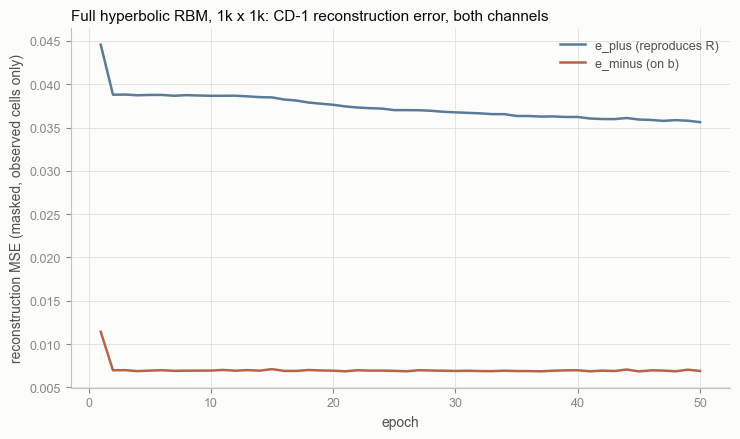

saved: outputs/43_full_hyperbolic_rbm_1k_training_loss.png


In [11]:
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams["font.family"] = ["Arial", "Helvetica", "DejaVu Sans"]

fig, ax = plt.subplots(figsize=(7.5, 4.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(range(1, EPOCHS + 1), history_plus, color="#5b7c99", linewidth=1.8, label="e_plus (reproduces R)", zorder=3)
ax.plot(range(1, EPOCHS + 1), history_minus, color="#b4654a", linewidth=1.8, label="e_minus (on b)", zorder=3)
ax.set_xlabel("epoch", color=INK_SECONDARY, fontsize=10)
ax.set_ylabel("reconstruction MSE (masked, observed cells only)", color=INK_SECONDARY, fontsize=10)
ax.set_title("Full hyperbolic RBM, 1k x 1k: CD-1 reconstruction error, both channels", color=INK_PRIMARY, fontsize=11, loc="left")
ax.legend(loc="best", frameon=False, fontsize=9, labelcolor=INK_SECONDARY)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color(BASELINE)
ax.tick_params(colors=INK_MUTED, labelsize=9)
ax.grid(color=GRID, linewidth=0.6, zorder=0)
plt.tight_layout()
plt.savefig(out_dir / "43_full_hyperbolic_rbm_1k_training_loss.png", dpi=150, facecolor=SURFACE)
plt.show()
print("saved: outputs/43_full_hyperbolic_rbm_1k_training_loss.png")

## Step 10 -- save outputs

In [12]:
import json

metrics = {
    "r_baseline": {"rmse": rmse_plus, "mae": mae_plus},
    "d_hyperbolic": {"rmse": rmse_hyp, "mae": mae_hyp},
    "diff_d_minus_r": {"rmse": rmse_hyp - rmse_plus, "mae": mae_hyp - mae_plus},
    "correction_term": {"mean": correction_mean, "std": correction_std},
    "mean_abs_B": {"start": mean_abs_B_start, "after_training": mean_abs_B_final},
    "n_train": int(len(train_hyp)),
    "n_test": int(len(test_hyp)),
    "n_users": n_users,
    "n_movies": n_movies,
    "n_hidden": N_HIDDEN,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "lr": LR,
    "seed_weights_init": 44,
    "seed_shuffle": 44,
}
metrics_path = out_dir / "43_full_hyperbolic_rbm_1k_results.json"
with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)
print(f"saved: {metrics_path}")

predictions = pd.DataFrame({
    "userId": test_hyp["userId"].values,
    "movieId": test_hyp["movieId"].values,
    "rating_true": rating_true,
    "r_hat_plus": r_plus_pred,
    "r_hat": r_hat,
})
predictions_path = out_dir / "43_full_hyperbolic_rbm_1k_predictions.csv"
predictions.to_csv(predictions_path, index=False)
print(f"saved: {predictions_path}  ({len(predictions):,} rows)")

weights_path = out_dir / "43_full_hyperbolic_rbm_1k_weights.npz"
np.savez(
    weights_path,
    W_plus=rbm_plus.W.numpy(), c_plus=rbm_plus.hbias.numpy(), d_plus=rbm_plus.vbias.numpy(),
    W_minus=rbm_minus.W.numpy(), c_minus=rbm_minus.hbias.numpy(), d_minus=rbm_minus.vbias.numpy(),
)
print(f"saved: {weights_path}")

for p in (metrics_path, predictions_path, weights_path):
    size_mb = p.stat().st_size / (1024 * 1024)
    print(f"{p.name}: {size_mb:.3f} MB")

saved: /Users/yixuan/Boltzmann Machine in Movie Lens/rbm-recsys/outputs/43_full_hyperbolic_rbm_1k_results.json


saved: /Users/yixuan/Boltzmann Machine in Movie Lens/rbm-recsys/outputs/43_full_hyperbolic_rbm_1k_predictions.csv  (123,474 rows)
saved: /Users/yixuan/Boltzmann Machine in Movie Lens/rbm-recsys/outputs/43_full_hyperbolic_rbm_1k_weights.npz
43_full_hyperbolic_rbm_1k_results.json: 0.001 MB
43_full_hyperbolic_rbm_1k_predictions.csv: 4.087 MB
43_full_hyperbolic_rbm_1k_weights.npz: 0.987 MB


# Diagnostic: does the e_minus correction carry rating information?

Everything below is diagnostic only, fitted on the test set -- it is not a reported result. It asks
whether the hyperbolic correction term `C = 4.5 * (v_hat_minus[j] - b_u)` tracks the residual the
e_plus channel leaves behind, using the test predictions already computed above.

## Diagnostic 1 -- correlation between the correction and the residual

`R = true rating - r_hat_plus` (unclipped). Pearson correlation between `C` and `R` over all
123,474 test ratings.

In [13]:
from scipy import stats as _stats

R_resid = rating_true - r_plus_unclipped
diag_corr_C_R, diag_corr_C_R_p = _stats.pearsonr(correction, R_resid)
print(f"Pearson corr(C, R): {diag_corr_C_R:.4f}  (p={diag_corr_C_R_p:.2e}, n={len(R_resid):,})")

Pearson corr(C, R): -0.3746  (p=0.00e+00, n=123,474)


## Diagnostic 2 -- best-fit scale for the correction

Least squares, no intercept: `R = lambda * C`. With intercept: `R = alpha + lambda * C`. For each,
clip `r_hat_plus + alpha + lambda * C` to [0.5, 5.0] and score against the true rating. Diagnostic
numbers only -- fitted on the test set, not a reported result.

In [14]:
lambda_no_intercept = float(np.dot(R_resid, correction) / np.dot(correction, correction))
alpha_no_intercept = 0.0

C_mean, R_mean = correction.mean(), R_resid.mean()
C_centered, R_centered = correction - C_mean, R_resid - R_mean
lambda_with_intercept = float(np.dot(C_centered, R_centered) / np.dot(C_centered, C_centered))
alpha_with_intercept = float(R_mean - lambda_with_intercept * C_mean)

r_fit_no_intercept = np.clip(r_plus_unclipped + alpha_no_intercept + lambda_no_intercept * correction, 0.5, 5.0)
rmse_fit_no_intercept = float(np.sqrt(np.mean((r_fit_no_intercept - rating_true) ** 2)))
mae_fit_no_intercept = float(np.mean(np.abs(r_fit_no_intercept - rating_true)))

r_fit_with_intercept = np.clip(r_plus_unclipped + alpha_with_intercept + lambda_with_intercept * correction, 0.5, 5.0)
rmse_fit_with_intercept = float(np.sqrt(np.mean((r_fit_with_intercept - rating_true) ** 2)))
mae_fit_with_intercept = float(np.mean(np.abs(r_fit_with_intercept - rating_true)))

print("DIAGNOSTIC (fitted on the test set, not a reported result):")
print(f"  no intercept:   lambda={lambda_no_intercept:.4f}  ->  RMSE={rmse_fit_no_intercept:.4f}  MAE={mae_fit_no_intercept:.4f}")
print(f"  with intercept: alpha={alpha_with_intercept:.4f}  lambda={lambda_with_intercept:.4f}  ->  RMSE={rmse_fit_with_intercept:.4f}  MAE={mae_fit_with_intercept:.4f}")

DIAGNOSTIC (fitted on the test set, not a reported result):
  no intercept:   lambda=-0.8496  ->  RMSE=0.7809  MAE=0.5928
  with intercept: alpha=-0.0390  lambda=-0.8438  ->  RMSE=0.7799  MAE=0.5948


## Diagnostic 3 -- does e_minus vary by movie at all

For each user, the standard deviation of `v_hat_minus[j]` across that user's test movies (only
users with 2+ test ratings have a defined std). Mean and median across users, in `v_hat_minus`
units and in stars (x4.5).

In [15]:
diag_df = pd.DataFrame({
    "userId": test_hyp["userId"].values,
    "movieId": test_hyp["movieId"].values,
    "rating_true": rating_true,
    "e_plus_pred": e_plus_pred,
    "e_minus_pred": e_minus_pred,
    "correction": correction,
})

per_user_std = diag_df.groupby("userId")["e_minus_pred"].std()  # NaN for users with a single test rating
per_user_std = per_user_std.dropna()

mean_std_vhatminus = float(per_user_std.mean())
median_std_vhatminus = float(per_user_std.median())
mean_std_stars = mean_std_vhatminus * 4.5
median_std_stars = median_std_vhatminus * 4.5

print(f"per-user std of v_hat_minus across test movies (n_users={len(per_user_std):,}):")
print(f"  mean:   {mean_std_vhatminus:.4f}  ({mean_std_stars:.4f} stars)")
print(f"  median: {median_std_vhatminus:.4f}  ({median_std_stars:.4f} stars)")

per-user std of v_hat_minus across test movies (n_users=1,000):
  mean:   0.0103  (0.0463 stars)
  median: 0.0104  (0.0468 stars)


## Diagnostic 4 -- within-user signal

For each user with at least 5 test ratings, Pearson correlation between `v_hat_minus[j]` and the
true rating across that user's test movies (skip a user if either side has zero variance). Same for
`v_hat_plus[j]` as a reference.

In [16]:
def per_user_correlation(df, value_col, min_n=5):
    corrs = []
    for uid, g in df.groupby("userId"):
        if len(g) < min_n:
            continue
        x, y = g[value_col].values, g["rating_true"].values
        if np.std(x) == 0 or np.std(y) == 0:
            continue
        corrs.append(np.corrcoef(x, y)[0, 1])
    return np.array(corrs)

corrs_minus = per_user_correlation(diag_df, "e_minus_pred")
corrs_plus = per_user_correlation(diag_df, "e_plus_pred")

n_users_minus, median_corr_minus, mean_corr_minus = len(corrs_minus), float(np.median(corrs_minus)), float(np.mean(corrs_minus))
n_users_plus, median_corr_plus, mean_corr_plus = len(corrs_plus), float(np.median(corrs_plus)), float(np.mean(corrs_plus))

print(f"v_hat_minus vs true rating, within user (n_users={n_users_minus:,}): median={median_corr_minus:.4f}  mean={mean_corr_minus:.4f}")
print(f"v_hat_plus  vs true rating, within user (n_users={n_users_plus:,}): median={median_corr_plus:.4f}  mean={mean_corr_plus:.4f}  (reference)")

v_hat_minus vs true rating, within user (n_users=1,000): median=0.0791  mean=0.0842
v_hat_plus  vs true rating, within user (n_users=1,000): median=0.5025  mean=0.4892  (reference)


## Diagnostic summary table

In [17]:
print(f"{'diagnostic':38s} {'value':>12s}")
print(f"{'corr(C, R), all test ratings':38s} {diag_corr_C_R:>12.4f}")
print(f"{'lambda, no intercept':38s} {lambda_no_intercept:>12.4f}")
print(f"{'  -> RMSE':38s} {rmse_fit_no_intercept:>12.4f}")
print(f"{'  -> MAE':38s} {mae_fit_no_intercept:>12.4f}")
print(f"{'alpha, with intercept':38s} {alpha_with_intercept:>12.4f}")
print(f"{'lambda, with intercept':38s} {lambda_with_intercept:>12.4f}")
print(f"{'  -> RMSE':38s} {rmse_fit_with_intercept:>12.4f}")
print(f"{'  -> MAE':38s} {mae_fit_with_intercept:>12.4f}")
print(f"{'mean per-user std v_hat_minus':38s} {mean_std_vhatminus:>12.4f}")
print(f"{'median per-user std v_hat_minus':38s} {median_std_vhatminus:>12.4f}")
print(f"{'mean per-user std, in stars':38s} {mean_std_stars:>12.4f}")
print(f"{'median per-user std, in stars':38s} {median_std_stars:>12.4f}")
print(f"{'n_users, within-user corr (minus)':38s} {n_users_minus:>12d}")
print(f"{'median within-user corr (minus)':38s} {median_corr_minus:>12.4f}")
print(f"{'mean within-user corr (minus)':38s} {mean_corr_minus:>12.4f}")
print(f"{'n_users, within-user corr (plus)':38s} {n_users_plus:>12d}")
print(f"{'median within-user corr (plus)':38s} {median_corr_plus:>12.4f}")
print(f"{'mean within-user corr (plus)':38s} {mean_corr_plus:>12.4f}")

diagnostic                                    value
corr(C, R), all test ratings                -0.3746
lambda, no intercept                        -0.8496
  -> RMSE                                    0.7809
  -> MAE                                     0.5928
alpha, with intercept                       -0.0390
lambda, with intercept                      -0.8438
  -> RMSE                                    0.7799
  -> MAE                                     0.5948
mean per-user std v_hat_minus                0.0103
median per-user std v_hat_minus              0.0104
mean per-user std, in stars                  0.0463
median per-user std, in stars                0.0468
n_users, within-user corr (minus)              1000
median within-user corr (minus)              0.0791
mean within-user corr (minus)                0.0842
n_users, within-user corr (plus)               1000
median within-user corr (plus)               0.5025
mean within-user corr (plus)                 0.4892


## Add diagnostic numbers to the existing metrics JSON

Loads the JSON already saved above, adds a new `diagnostic_e_minus` key, keeps every existing key
unchanged.

In [18]:
with open(metrics_path) as f:
    metrics_updated = json.load(f)

metrics_updated["diagnostic_e_minus"] = {
    "note": "diagnostic only, fitted on the test set -- not a reported result",
    "corr_C_R": diag_corr_C_R,
    "best_scale_no_intercept": {
        "lambda": lambda_no_intercept,
        "rmse": rmse_fit_no_intercept,
        "mae": mae_fit_no_intercept,
    },
    "best_scale_with_intercept": {
        "alpha": alpha_with_intercept,
        "lambda": lambda_with_intercept,
        "rmse": rmse_fit_with_intercept,
        "mae": mae_fit_with_intercept,
    },
    "per_user_std_v_hat_minus": {
        "n_users": len(per_user_std),
        "mean": mean_std_vhatminus,
        "median": median_std_vhatminus,
        "mean_stars": mean_std_stars,
        "median_stars": median_std_stars,
    },
    "within_user_correlation": {
        "v_hat_minus": {"n_users": n_users_minus, "median": median_corr_minus, "mean": mean_corr_minus},
        "v_hat_plus_reference": {"n_users": n_users_plus, "median": median_corr_plus, "mean": mean_corr_plus},
    },
}

with open(metrics_path, "w") as f:
    json.dump(metrics_updated, f, indent=2)
print(f"updated: {metrics_path}")
print(f"keys: {list(metrics_updated.keys())}")

updated: /Users/yixuan/Boltzmann Machine in Movie Lens/rbm-recsys/outputs/43_full_hyperbolic_rbm_1k_results.json
keys: ['r_baseline', 'd_hyperbolic', 'diff_d_minus_r', 'correction_term', 'mean_abs_B', 'n_train', 'n_test', 'n_users', 'n_movies', 'n_hidden', 'batch_size', 'epochs', 'lr', 'seed_weights_init', 'seed_shuffle', 'diagnostic_e_minus']
